# Regressione e clustering sui pinguini con Gemini · soluzione
**Script intelligenti: sviluppare modelli di Machine Learning con il codice**

I dati: gli stessi **Palmer Penguins** dell'incontro 2 (Horst, Hill e Gorman, CC0). Per la sfida in più,
i dati **Gapminder** (Gapminder Foundation, CC BY 4.0).

Oggi non scriviamo codice a mano: lo scrive **Gemini**, l'assistente di Colab. Il nostro lavoro è chiedere bene e
controllare il risultato.

| | |
|---|---|
| **1 · Chiedi chiaro** | che cosa vuoi, con quali dati, in che forma vuoi il risultato |
| **2 · Leggi** | il codice proposto, anche senza capirlo tutto: quali dati usa? che cosa calcola? |
| **3 · Esegui** | e guarda che cosa succede, errori compresi |
| **4 · Controlla** | il risultato torna con quello che sai? I numeri sono plausibili? |

> **Versione per il docente.** Ogni tappa ha il codice di una soluzione possibile, già eseguito. Gemini
> scriverà codice diverso, a volte con nomi diversi: va bene, conta che i risultati tornino.

## Come chiedere a Gemini
1. In una cella di codice vuota, cliccate su **genera** (oppure aprite il pannello di Gemini, in alto a destra).
2. Scrivete la richiesta in italiano: potete copiare il prompt di esempio.
3. Leggete il codice proposto prima di accettarlo.
4. Eseguitelo con ▶ e guardate il risultato.

*Se Gemini non è disponibile:* usate ChatGPT o Claude in un'altra scheda e incollate qui il codice.

## Preparazione
Eseguite questa cella con ▶: scarica i dati. Se il download non funziona, caricate i file a mano dal pannello **File** (l'icona a forma di cartella a sinistra).

In [1]:
# Scarica i file dei dati nella cartella di lavoro di Colab.
import os
import urllib.request

if not os.path.exists("penguins.csv"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/matteolimoncini/script-intelligenti/main/incontro-3/dati/penguins.csv", "penguins.csv")
if not os.path.exists("gapminder.csv"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/matteolimoncini/script-intelligenti/main/incontro-3/dati/gapminder.csv", "gapminder.csv")
print("File pronti:", "penguins.csv", "gapminder.csv")

File pronti: penguins.csv gapminder.csv


## Tappa 1 · Una retta per il peso
**Prompt di esempio:**

> Carica penguins.csv con pandas ed elimina le righe senza peso. Fai uno scatter del peso in funzione della
> lunghezza della pinna. Addestra una regressione lineare (80/20, random_state=42), disegna la retta sul grafico e
> dimmi pendenza, MAE, RMSE e R² sul test.

Pendenza: 49.9 g per mm   Intercetta: -5817
MAE:  288 g
RMSE: 356 g
R²:   0.78


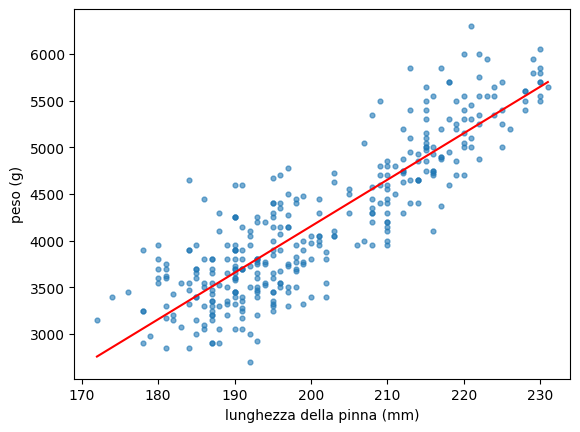

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("penguins.csv").dropna(subset=["body_mass_g"])
X = df[["flipper_length_mm"]]
y = df["body_mass_g"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

retta = LinearRegression().fit(X_train, y_train)
prev = retta.predict(X_test)
print("Pendenza:", round(retta.coef_[0], 1), "g per mm   Intercetta:", round(retta.intercept_))
print("MAE: ", round(mean_absolute_error(y_test, prev)), "g")
print("RMSE:", round(mean_squared_error(y_test, prev) ** 0.5), "g")
print("R²:  ", round(r2_score(y_test, prev), 2))

plt.scatter(X, y, s=12, alpha=0.6)
xs = pd.DataFrame({"flipper_length_mm": np.linspace(X.min().iloc[0], X.max().iloc[0], 50)})
plt.plot(xs, retta.predict(xs), color="red")
plt.xlabel("lunghezza della pinna (mm)"); plt.ylabel("peso (g)")
plt.show()

**Poi:**

> Quanto pesa secondo il modello un pinguino con la pinna di 200 mm? E di 100 mm? E quanto sbaglierebbe un modello che
> prevede sempre il peso medio?

In [3]:
print("Pinna 200 mm:", round(retta.predict(pd.DataFrame({"flipper_length_mm": [200]}))[0]), "g")
print("Pinna 100 mm:", round(retta.predict(pd.DataFrame({"flipper_length_mm": [100]}))[0]), "g")
media = np.full(len(y_test), y_train.mean())
print("Sempre la media: MAE", round(mean_absolute_error(y_test, media)), "g")

Pinna 200 mm: 4153 g
Pinna 100 mm: -832 g
Sempre la media: MAE 624 g


**Controllate**
- Quanti grammi in più per ogni millimetro di pinna?
- MAE e RMSE: quale è più grande? Perché?
- Il peso previsto per una pinna di 100 mm ha senso?

**Che cosa si deve vedere:** circa 50 g per ogni mm di pinna; MAE circa 288 g, RMSE circa 356 g (l'RMSE è più grande perché
pesa di più gli errori grandi), R² circa 0,78. Pinna di 200 mm: circa 4160 g. Pinna di 100 mm: circa −830 g, un peso
negativo: fuori dai dati la retta non vale (estrapolazione). Un modello che prevede sempre la media sbaglia di circa
624 g: la retta dimezza l'errore.

## Tappa 2 · Più variabili
**Prompt di esempio:**

> Rifai la regressione usando lunghezza e profondità del becco, lunghezza della pinna e la specie codificata con
> one-hot (sempre 80/20, random_state=42). Confronta MAE e R² con il modello di prima e mostrami i coefficienti.

In [4]:
X2 = pd.get_dummies(df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "species"]],
                    columns=["species"], drop_first=True, dtype=int)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)
multipla = LinearRegression().fit(X2_train, y2_train)
prev2 = multipla.predict(X2_test)
print("MAE:", round(mean_absolute_error(y2_test, prev2)), "g   R²:", round(r2_score(y2_test, prev2), 2))
pd.Series(multipla.coef_, index=X2.columns).round(1)

MAE: 259 g   R²: 0.83


bill_length_mm         38.1
bill_depth_mm         149.7
flipper_length_mm      17.9
species_Chinstrap    -491.1
species_Gentoo       1060.6
dtype: float64

**Domande**
- Il modello è migliorato? Di quanto?
- Come si leggono i coefficienti della specie? (rispetto a quale specie?)

**Che cosa si deve vedere:** MAE circa 259 g e R² circa 0,83, meglio della sola pinna. Con drop_first la specie di riferimento
è Adelie: il coefficiente di Gentoo dice quanti grammi in più pesa un Gentoo rispetto a un Adelie con le stesse misure
(circa +1060 g), quello di Chinstrap quanti in meno (circa −490 g).

## Tappa 3 · K-means senza la specie
**Prompt di esempio:**

> Togli la colonna della specie. Standardizza le quattro misure e applica K-means con 3 gruppi (random_state=0).
> Confronta i gruppi trovati con le specie vere in una tabella incrociata e fai un grafico colorato per gruppo accanto
> a uno colorato per specie.

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

misure = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
dati = pd.read_csv("penguins.csv").dropna(subset=misure)
Z = StandardScaler().fit_transform(dati[misure])
dati["gruppo"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)
pd.crosstab(dati["species"], dati["gruppo"])

gruppo,0,1,2
species,,,
Adelie,127,0,24
Chinstrap,5,0,63
Gentoo,0,123,0


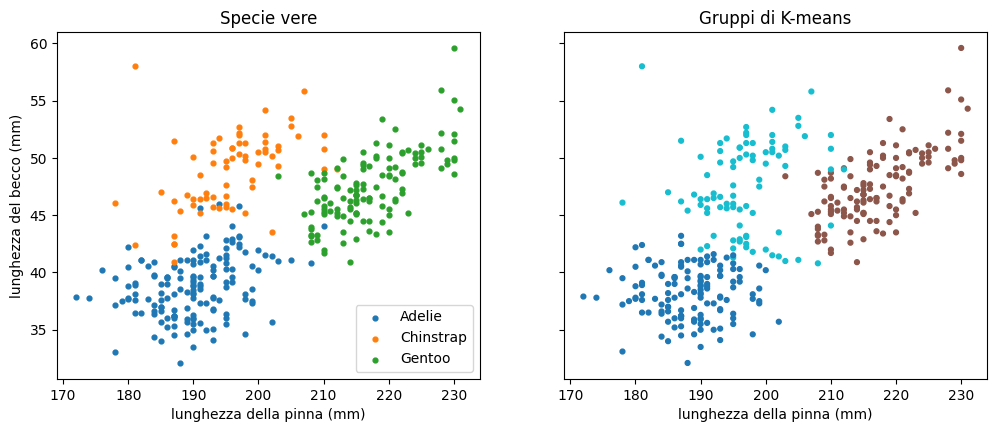

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for specie, g in dati.groupby("species"):
    axs[0].scatter(g["flipper_length_mm"], g["bill_length_mm"], s=12, label=specie)
axs[0].set_title("Specie vere"); axs[0].legend()
axs[1].scatter(dati["flipper_length_mm"], dati["bill_length_mm"], s=12, c=dati["gruppo"], cmap="tab10")
axs[1].set_title("Gruppi di K-means")
for a in axs:
    a.set_xlabel("lunghezza della pinna (mm)")
axs[0].set_ylabel("lunghezza del becco (mm)")
plt.show()

**Poi:**

> Ripeti senza standardizzare le misure.

In [7]:
dati["gruppo_grezzo"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(dati[misure])
pd.crosstab(dati["species"], dati["gruppo_grezzo"])

gruppo_grezzo,0,1,2
species,,,
Adelie,0,116,35
Chinstrap,0,53,15
Gentoo,68,1,54


**Domande**
- K-means ha ritrovato le specie? Quali si confondono?
- Senza standardizzare, che cosa cambia? Perché?

**Che cosa si deve vedere:** con lo scaling i 123 Gentoo finiscono tutti nello stesso gruppo, 24 Adelie finiscono con i
Chinstrap: circa il 92% dei pinguini sta nel gruppo «giusto». I numeri dei gruppi (0, 1, 2) sono arbitrari. Senza
scaling si scende a circa il 69%: il peso in grammi domina le distanze.

## Tappa 4 · Quanti gruppi?
**Prompt di esempio:**

> Prova K-means sulle misure standardizzate con k da 2 a 6, fai il grafico dell'inerzia (metodo del gomito) e calcola
> la silhouette per ogni k. Poi con k = 4 dimmi che cosa hanno in comune i pinguini di ogni gruppo, confrontando con
> specie e sesso.

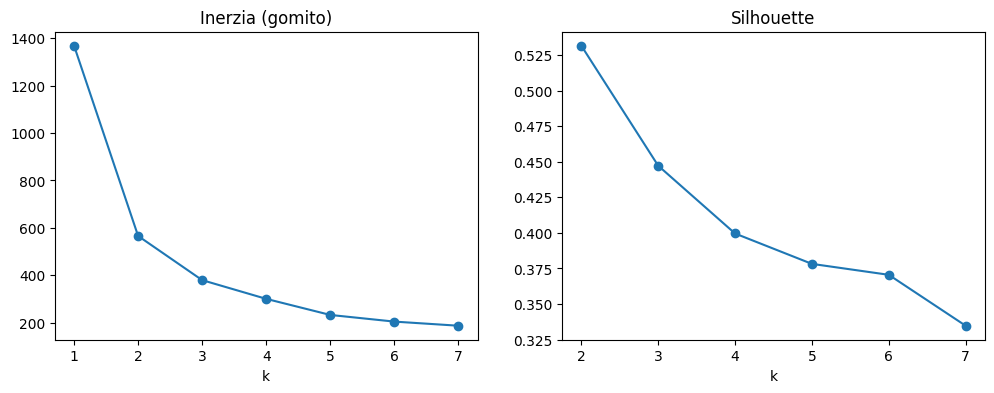

{2: 0.53, 3: 0.45, 4: 0.4, 5: 0.38, 6: 0.37, 7: 0.33}

In [8]:
from sklearn.metrics import silhouette_score

ks = range(1, 8)
inerzia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z).inertia_ for k in ks]
sil = {k: silhouette_score(Z, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)) for k in range(2, 8)}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(list(ks), inerzia, "o-"); axs[0].set_title("Inerzia (gomito)"); axs[0].set_xlabel("k")
axs[1].plot(list(sil), list(sil.values()), "o-"); axs[1].set_title("Silhouette"); axs[1].set_xlabel("k")
plt.show()
{k: round(v, 2) for k, v in sil.items()}

In [9]:
dati["gruppo4"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(Z)
pd.crosstab([dati["species"], dati["sex"]], dati["gruppo4"])

gruppo4            0   1   2   3
species   sex                   
Adelie    female   0   0  73   0
          male    23   0  50   0
Chinstrap female  29   0   5   0
          male    34   0   0   0
Gentoo    female   0  56   0   2
          male     0   6   0  55

**Domande**
- Quale k preferisce la silhouette? Corrisponde al numero di specie?
- Con k = 4, che cosa distingue i due gruppi in cui finiscono i Gentoo?

**Che cosa si deve vedere:** la silhouette è massima con k = 2 (0,53: Gentoo da una parte, tutti gli altri dall'altra), poi
k = 3 (0,45). L'algoritmo non sa quante specie ci sono. Con k = 4 i Gentoo si dividono quasi esattamente per sesso:
K-means ha trovato una struttura che non avevamo chiesto.

## Sfide in più, per chi finisce prima
> **Al contrario:** predici la lunghezza della pinna dal peso. La pendenza è l'inverso di prima?

> **Solo il becco:** K-means con k = 3 sulle sole misure del becco, standardizzate. Ritrova ancora le specie?

> **Gapminder:** carica gapminder.csv, tieni l'anno 2007 e fai una regressione dell'aspettativa di vita (lifeExp) sul
> reddito per abitante (gdpPercap), prima così com'è e poi sul suo logaritmo. Quale funziona meglio?

**Domande su Gapminder**
- Allora basta arricchirsi per vivere di più? Quale variabile nascosta potrebbe far crescere insieme reddito e
  aspettativa di vita?
- La causa potrebbe andare anche nell'altro verso?
- Trovate due paesi con un reddito simile e un'aspettativa di vita molto diversa: che cosa li distingue?

In [10]:
inv = LinearRegression().fit(df[["body_mass_g"]], df["flipper_length_mm"])
print("mm di pinna per ogni grammo:", round(inv.coef_[0], 4), "  (1 / 49,7 =", round(1 / 49.7, 4), ")")

mm di pinna per ogni grammo: 0.0153   (1 / 49,7 = 0.0201 )


In [11]:
Zb = StandardScaler().fit_transform(dati[["bill_length_mm", "bill_depth_mm"]])
pd.crosstab(dati["species"], KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Zb))

col_0,0,1,2
species,,,
Adelie,0,147,4
Chinstrap,9,5,54
Gentoo,116,1,6


In [12]:
gap = pd.read_csv("gapminder.csv")
g07 = gap[gap["year"] == 2007]
for nome, x in [("reddito", g07[["gdpPercap"]]), ("log10 del reddito", np.log10(g07[["gdpPercap"]]))]:
    m = LinearRegression().fit(x, g07["lifeExp"])
    print(nome, " R² =", round(r2_score(g07["lifeExp"], m.predict(x)), 2))

reddito  R² = 0.46
log10 del reddito  R² = 0.65


**Che cosa si deve vedere:** la pendenza inversa non è 1/49,7: la retta che predice la pinna dal peso è un'altra retta (minimizza
gli errori in orizzontale, non in verticale). Gapminder 2007 (142 paesi): R² 0,46 sul reddito, 0,65 sul suo
logaritmo. Reddito e aspettativa di vita vanno insieme, ma non è detto che uno causi l'altra: istruzione, ospedali,
acqua potabile e vaccini crescono con il reddito (la variabile nascosta dell'incontro 2), e una popolazione più sana
produce anche più reddito. Sotto la retta ci sono paesi come il Sudafrica e la Nigeria, colpiti dall'AIDS negli anni
2000.

## Per finire
Avete predetto un numero, valutato l'errore con MAE, RMSE e R², visto i limiti dell'estrapolazione e cercato gruppi
senza label con K-means. **Nell'incontro 4** vedremo che cosa succede ai modelli nel mondo reale. Portate un'idea di
attività per la vostra materia.